# Assignment 1 — EDA & Baseline
## Fake or Real: The Impostor Hunt in Texts (Kaggle)

**Group:** 65 · **Member:** Yakup Furkan Konuk (22118080089) · **Course:** CENG313

**Notebook outline**
0. Setup
1. Problem definition
2. Data overview
3. Exploratory data analysis
4. Preprocessing
5. Baseline model
6. Kaggle submission
7. Conclusion

## 0. Setup
Reusable code lives in `src/` (`data.py`, `utils.py`, `models.py`) and is imported here.
On Colab the cells below clone this repository and download the data with the Kaggle API
(upload your `kaggle.json` when asked). Locally, put the Kaggle files under `data/`.

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules

REPO_URL = "https://github.com/ceng313-2026/GROUP65_CENG313.git"
REPO_DIR = "GROUP65_CENG313"

if IN_COLAB:
    if not os.path.exists(REPO_DIR):
        !git clone {REPO_URL}
    %cd {REPO_DIR}
    !pip -q install kaggle

In [2]:
COMPETITION = "fake-or-real-the-impostor-hunt"
DATA_DIR = "data"

import glob
if not glob.glob(os.path.join(DATA_DIR, "**", "train.csv"), recursive=True):
    if IN_COLAB and not os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
        from google.colab import files
        files.upload()  # choose kaggle.json
        !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    !kaggle competitions download -c {COMPETITION} -p {DATA_DIR}
    !cd {DATA_DIR} && unzip -q -o "*.zip" && rm -f *.zip

In [3]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split

sys.path.append(".")
from src.data import find_data_dir, load_split, to_long_format, get_target
from src.utils import set_seed, features_frame, save_submission
from src.models import ALL_BASELINES, cross_validate, FeatureDiffLR, TfidfDiffLR

set_seed(42)
pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.figsize"] = (8, 4)

## 1. Problem definition

**Context.** The competition is organised by the European Space Agency to study two AI security
threats: *data poisoning* and *over-reliance* on Large Language Models (LLMs).
Articles from ESO's *The Messenger* journal were summarised by LLMs. For every article we get
**two summaries**: one written by a correctly working LLM (**real**) and one written by a
maliciously modified LLM (**fake**). The fake may be off-topic, overly excited, much longer,
or degrade into gibberish and foreign characters — but it may also be almost identical to the real one.

**Task.** For each pair (`file_1.txt`, `file_2.txt`) predict which file is the real one.

**Target variable.** `real_text_id` ∈ {1, 2} (in `train.csv`). Internally we also use the binary
target *"is file_1 the real one?"* (1/0).

**Evaluation metric.** **Accuracy** — the share of pairs where we pick the correct file.
A random guess therefore scores about 0.5.

**Important property.** This is a *pairwise* problem: we do not need to decide whether one text
is fake on its own, only which of the two is *more* likely to be real. All our features and models
compare the two texts of a pair.

## 2. Data overview
The data is not a single CSV: each article is a folder with two text files.
`src.data.load_split` turns the folders into one DataFrame with one row per pair.

In [4]:
DATA_ROOT = find_data_dir(DATA_DIR)
train = load_split(DATA_ROOT, "train")
test = load_split(DATA_ROOT, "test")
print("train shape:", train.shape, "| test shape:", test.shape)
train.head()

train shape: (95, 4) | test shape: (1068, 3)


,id,text_1,text_2,real_text_id
0,0,The VIRSA (Visible Infrared Survey Telescope Array) project produces vast amounts of high quality astronomical datasets used extensively across various fields within astronomy due to its rigorous ...,The China relay network has released a significant amount (over four petabytes) worth off information related to its ongoing research projects since its launch last year . This includes a wide ran...,1
1,1,China\nThe goal of this project involves achieving an accuracy level of just five parts per thousandths (or .5) within specific types of Chinese measurements using specific data sets or datasets w...,The project aims to achieve an accuracy level of 0.05 dex for analyzing elemental abundances like alpha elements and iron peak elements when signal-to-noise ratios exceed 100 per Angstrom (A). Red...,2
2,2,Scientists can learn about how galaxies form and evolve through two methods: observing many distant galaxies or studying specific nearby ones closely enough for detailed analysis using techniques ...,Dinosaur eggshells offer clues about what dinosaurs ate long ago; similarly paleontologists can use fossils from extinct species like dinosaurs or marine reptiles (such as ammonites) alongside the...,1
3,3,"China\nThe study suggests that multiple star systems play an essential role both during star formation's process as well as how they behave over time (their ""Chinese language""). The Very Large Tel...",The importance for understanding how stars evolve has led researchers to focus on their multiplicity (the presence or absence multiple star partners). The Very Large Telescope Interferometer (VLTI...,2
4,4,Dinosaur Rex was excited about his new toy set! He had so many dinosaurs he could build a whole museum! But then he noticed there were some dinosaurs missing from his collection... What happened?,"Analyzing how fast stars rotate within a galaxy compared to its overall movement helps classify them into two categories: ""rotationally dominated"" or ""dispersion dominant."" This classification pla...",2


**Interpretation.** We have only **95 labelled training pairs** (190 texts) but **1,068 test pairs**.
The test set is about 11 times larger than the training set, so the main risk of this project is
overfitting to a tiny training set.

In [5]:
print(train.dtypes)

id              int64
text_1            str
text_2            str
real_text_id    int64
dtype: object


**Interpretation.** `id` and `real_text_id` are integers; `text_1` and `text_2` are free text
(string/object columns). There are no numerical or categorical features — everything we use
must be extracted from the text itself.

In [6]:
long = to_long_format(train)          # one row per text (190 rows)
long["n_chars"] = long["text"].str.len()
long["n_words"] = long["text"].str.split().str.len()
long["label"] = long["is_real"].map({1: "real", 0: "fake"})
long.groupby("label")[["n_chars", "n_words"]].describe().T.round(1)

label             fake    real
n_chars count     95.0    95.0
        mean    3420.6  1446.2
        std     4747.1   500.3
        min        0.0   550.0
        25%     1386.5  1081.0
        50%     1852.0  1373.0
        75%     3066.5  1691.0
        max    40316.0  2734.0
n_words count     95.0    95.0
        mean     428.1   216.1
        std      480.1    77.2
        min        0.0    75.0
        25%      210.5   161.0
        50%      286.0   200.0
        75%      476.0   256.5
        max     4158.0   446.0

**Interpretation.** Real summaries are fairly uniform (75–446 words, median 200).
Fake summaries are much more variable: the median is higher (286 words) and the maximum is
over 4,000 words. The minimum of 0 shows that some fake texts are completely empty.

In [7]:
# Missing values and empty texts
print("Missing values (NaN) per column:")
print(train.isna().sum())
for name, df in [("train", train), ("test", test)]:
    e1 = (df["text_1"].str.len() == 0).sum(); e2 = (df["text_2"].str.len() == 0).sum()
    print(f"{name}: empty file_1 = {e1}, empty file_2 = {e2}")
empty_train = train[(train["text_1"].str.len() == 0) | (train["text_2"].str.len() == 0)]
empty_train[["id", "real_text_id"]].assign(
    empty_file=np.where(empty_train["text_1"].str.len() == 0, 1, 2))

Missing values (NaN) per column:
id              0
text_1          0
text_2          0
real_text_id    0
dtype: int64
train: empty file_1 = 1, empty file_2 = 1
test: empty file_1 = 0, empty file_2 = 1


,id,real_text_id,empty_file
10,10,1,2
14,14,2,1


**Interpretation.** There are no NaN values, but there are **empty texts**: 2 pairs in train and
1 pair in test. In both training cases the empty file is the **fake** one (`empty_file` ≠ `real_text_id`).
An empty summary is therefore not "missing data" but a symptom of the broken model, so we keep it
(see Preprocessing).

In [8]:
# Duplicates
print("duplicate pairs   — train:", train.duplicated(["text_1", "text_2"]).sum(),
      "| test:", test.duplicated(["text_1", "text_2"]).sum())
print("identical texts inside a pair — train:", (train.text_1 == train.text_2).sum(),
      "| test:", (test.text_1 == test.text_2).sum())
test_long = to_long_format(test)
tr_texts = long.loc[long.n_chars > 0, "text"]
te_texts = test_long.loc[test_long["text"].str.len() > 0, "text"]
print("duplicated texts  — train:", tr_texts.duplicated().sum(), "| test:", te_texts.duplicated().sum())
print("train texts that also appear in test:", tr_texts.isin(set(te_texts)).sum())

duplicate pairs   — train: 0 | test: 0
identical texts inside a pair — train: 0 | test: 1
duplicated texts  — train: 0 | test: 7
train texts that also appear in test: 0


**Interpretation.** Train has no duplicate pairs or texts, and no training text leaks into the test set,
so cross-validation on train is not inflated by duplicates. The test set contains a few repeated
texts and **one pair where both files are identical** — no model can do better than a coin flip on that pair.

## 3. Exploratory data analysis
### 3.1 Target balance

real_text_id
1    46
2    49
Name: count, dtype: int64


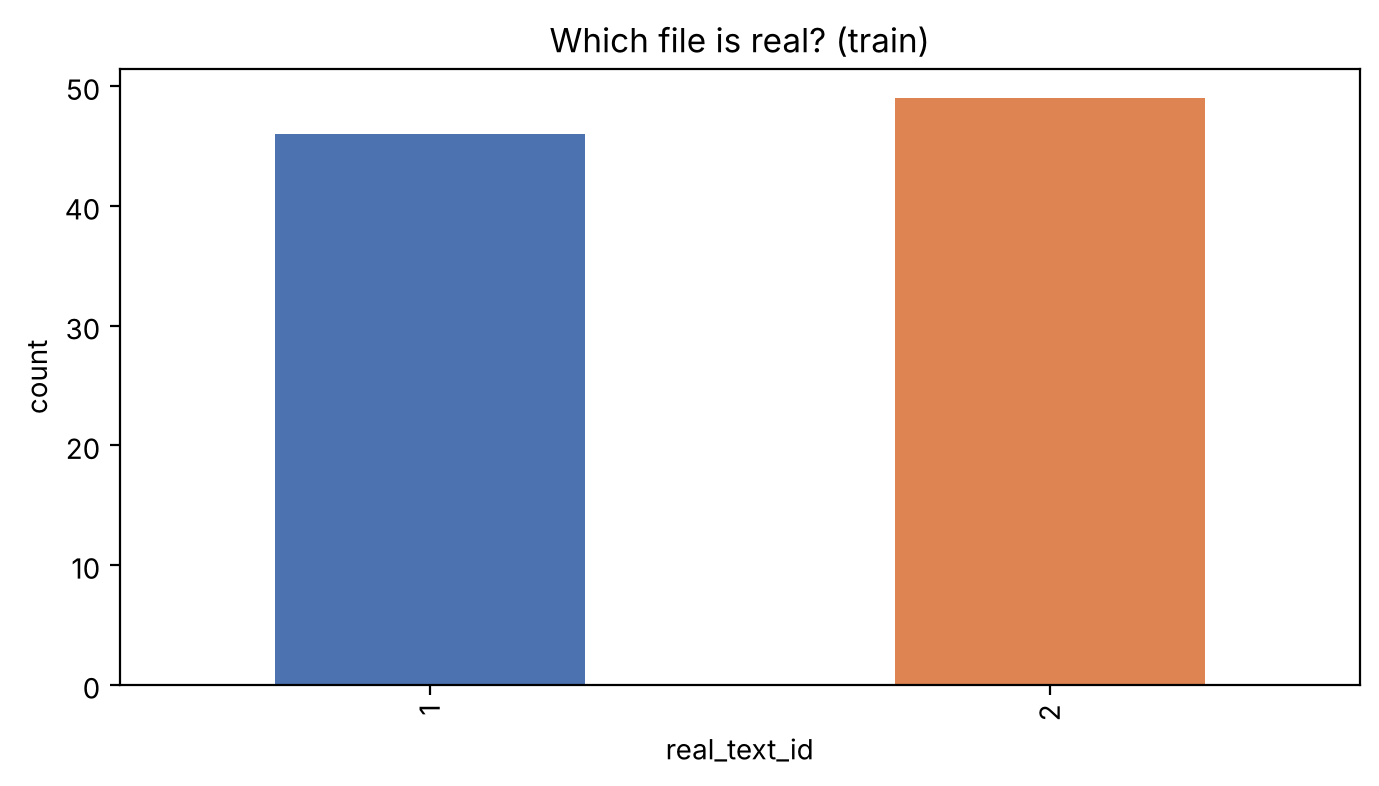

In [9]:
counts = train["real_text_id"].value_counts().sort_index()
print(counts)
counts.plot.bar(color=["#4C72B0", "#DD8452"])
plt.title("Which file is real? (train)"); plt.xlabel("real_text_id"); plt.ylabel("count"); plt.show()

**Interpretation.** The target is balanced: file 1 is real in 46 pairs and file 2 in 49 pairs.
Position carries no information, so always answering "2" would only reach about 52%,
and accuracy is a fair metric here (no need for class weighting).

### 3.2 Example pairs
Reading a few pairs is the fastest way to understand what "fake" looks like.

In [10]:
for _, row in train.sample(3, random_state=1).iterrows():
    real_k = int(row.real_text_id); fake_k = 3 - real_k
    print(f"===== article {row.id} =====")
    print("[REAL]", row[f"text_{real_k}"][:600], "...\n")
    print("[FAKE]", row[f"text_{fake_k}"][:600], "...\n")

===== article 40 =====
[REAL] Emsellem et al. (2007) created an estimator called lambda R to measure the projected angular momentum of galaxies. Later, in 2011, they showed how combining lambda R and epsilon effectively differentiates between slow and fast rotators. In their study, they define lambda R of Re based on values calculated within a specific region (Re).  For this calculation, we adapted their method to use all available spaxels for each integral field unit (IFU) in the observation area. This difference in sampling setup from the ATLAS3D approach was addressed by comparing our data with SAURON data and modeling  ...

[FAKE] Let's say Emsellem et al. (2007) introduced the estimator **Gruyère** to measure the projected specific angular momentum of galaxies, and Emsellem et al. (2011) further show how the combination of **Gruyère** and epsilon conveniently captures the kinematic boundary between slow rotators and fast rotators. They define **Gruyère** of Re as the value of **Gr

**Interpretation.** The fakes follow different patterns: some replace a technical term with a
nonsense word (e.g. "Gruyère"), some drift to an unrelated topic, some switch to a casual,
excited tone, and some start well and then degrade into random words and foreign characters.
These observations motivate the hand-crafted features below: length, punctuation (especially "!"),
non-Latin letters, digits and vocabulary richness.

### 3.3 Distributions and outliers
`src.utils.text_features` computes 14 simple statistics for every text.

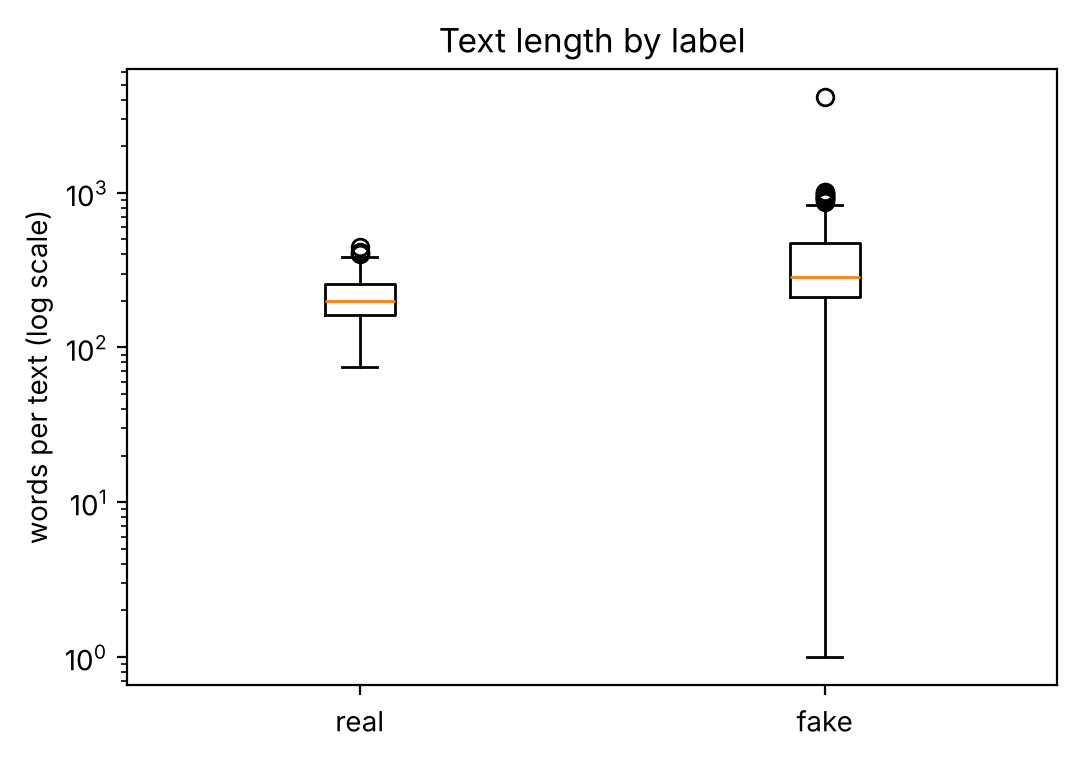

In [11]:
feats = features_frame(long["text"])
feats["label"] = long["label"].values

fig, ax = plt.subplots(figsize=(6, 4))
data = [feats.loc[feats.label == l, "n_words"].clip(lower=1) for l in ["real", "fake"]]
ax.boxplot(data)
ax.set_xticks([1, 2]); ax.set_xticklabels(["real", "fake"]); ax.set_yscale("log")
ax.set_ylabel("words per text (log scale)"); ax.set_title("Text length by label")
plt.show()

**Interpretation.** Real texts sit in a narrow band (75–450 words, middle half about 160–260). Fake texts have
a much wider spread and many **outliers**: some exceed 1,000 words (up to ~4,000), and two are empty
(drawn at 1 on the log scale).
These outliers are not errors in the data — they are exactly the behaviour of the corrupted model,
so we do **not** remove them.

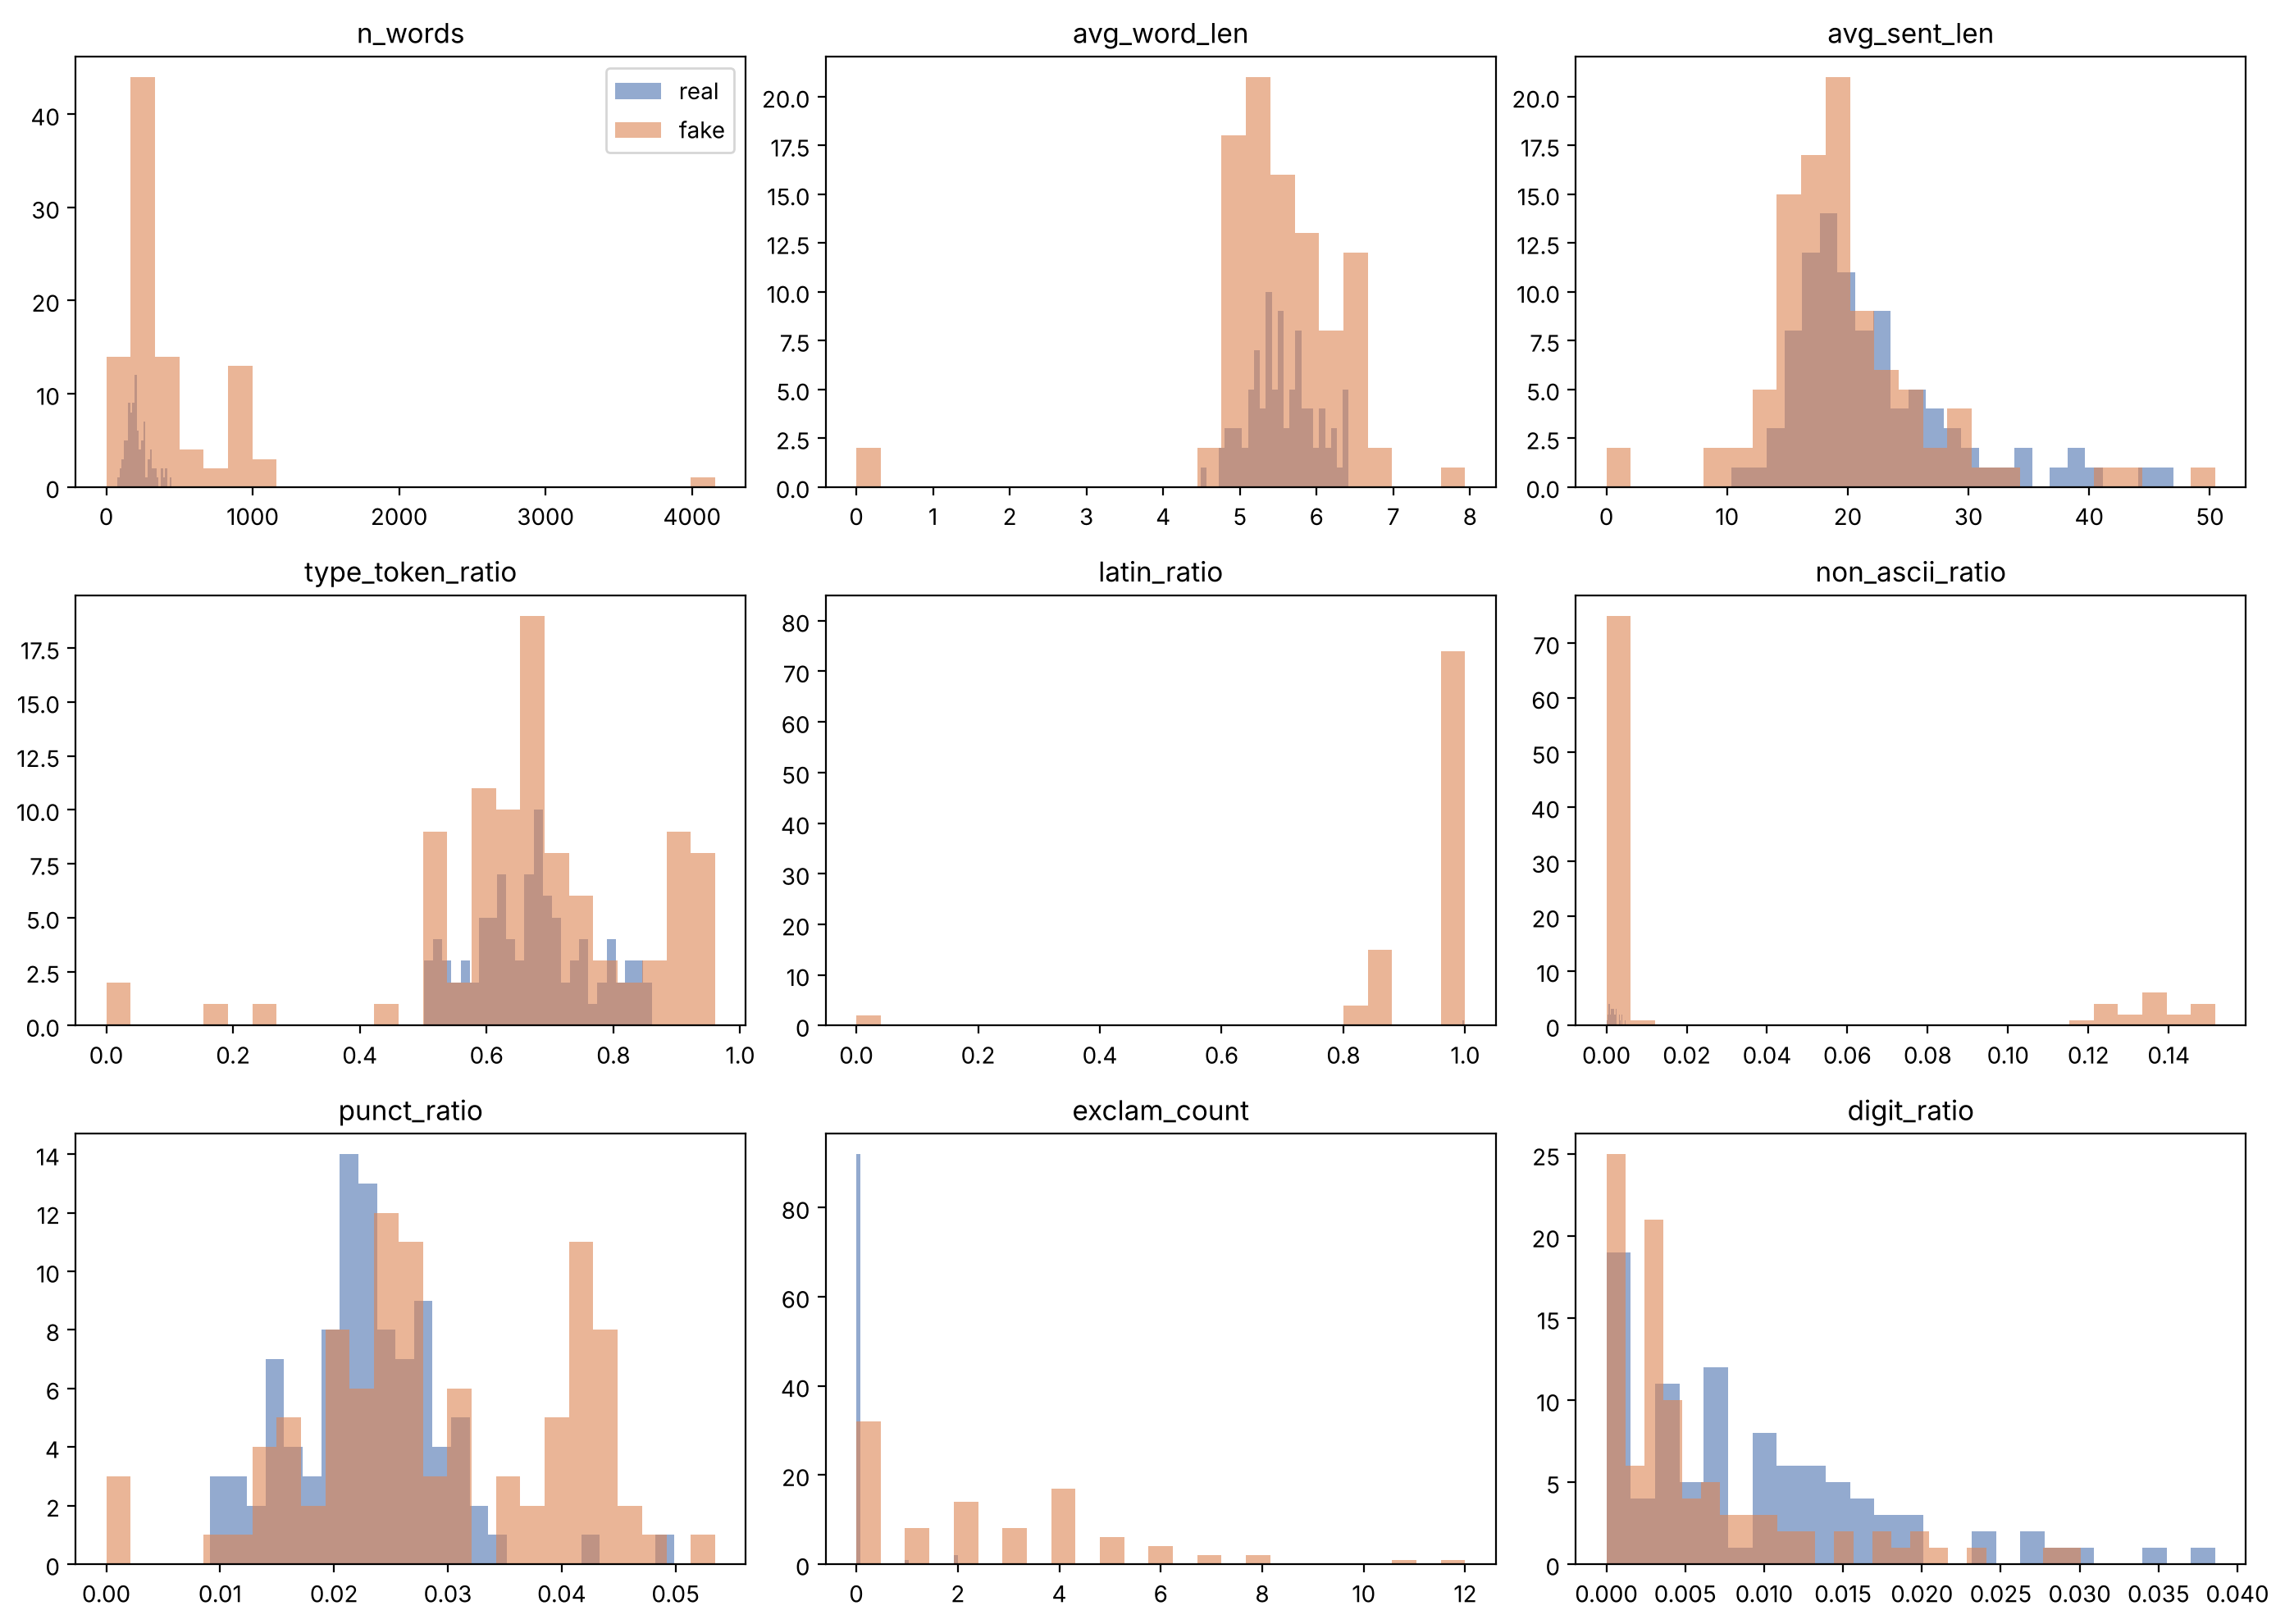

In [12]:
cols = ["n_words", "avg_word_len", "avg_sent_len", "type_token_ratio",
        "latin_ratio", "non_ascii_ratio", "punct_ratio", "exclam_count", "digit_ratio"]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, c in zip(axes.ravel(), cols):
    for lab, color in [("real", "#4C72B0"), ("fake", "#DD8452")]:
        ax.hist(feats.loc[feats.label == lab, c], bins=25, alpha=0.6, label=lab, color=color)
    ax.set_title(c)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

**Interpretation.**
- `n_words`, `exclam_count`: the fake (orange) distributions have long right tails — fakes are longer and use more "!".
- `latin_ratio`, `non_ascii_ratio`: almost all texts are 100% Latin, but a group of fakes has a lower Latin share / more non-ASCII characters.
- `digit_ratio`: real texts tend to contain more digits (dates, measurements).
- `avg_word_len`, `type_token_ratio`: the two distributions overlap almost completely — on their own these features do not separate real from fake.

### 3.4 Relationship with the target (paired view)
Because the task is pairwise, the most relevant question is: *inside a pair, is the real text
higher or lower than the fake on a feature?*

In [13]:
f1 = features_frame(train["text_1"]); f2 = features_frame(train["text_2"])
mask = (train["real_text_id"] == 1).values[:, None]
real_f = pd.DataFrame(np.where(mask, f1.values, f2.values), columns=f1.columns)
fake_f = pd.DataFrame(np.where(mask, f2.values, f1.values), columns=f1.columns)
pair_view = pd.DataFrame({
    "real > fake (%)": ((real_f > fake_f).mean() * 100).round(1),
    "real < fake (%)": ((real_f < fake_f).mean() * 100).round(1),
    "median real": real_f.median().round(3),
    "median fake": fake_f.median().round(3),
})
pair_view.sort_values("real > fake (%)")

,real > fake (%),real < fake (%),median real,median fake
exclam_count,1.1,65.3,0.000,2.000
newline_count,5.3,70.5,0.000,6.000
symbol_ratio,11.6,25.3,0.000,0.000
n_sentences,13.7,75.8,9.000,14.000
non_ascii_ratio,18.9,61.1,0.000,0.002
n_words,24.2,74.7,200.000,286.000
n_chars,26.3,73.7,1373.000,1852.000
latin_ratio,30.5,10.5,1.000,1.000
punct_ratio,33.7,66.3,0.023,0.027
avg_word_len,50.5,49.5,5.521,5.466


**Interpretation.** A feature is useful when one percentage is far from 50%.
- **Exclamation marks:** the fake has more "!" in 65% of pairs, the real text in only 1%.
- **Line breaks / sentences / length:** the fake is longer in about 75% of pairs.
- **Digits:** the real text has more digits in about 70% of pairs.
- **Latin ratio:** the real text is "more Latin" in 30% of pairs and less in 10%; in the remaining ~60% the two texts are tied (both 100% Latin). This explains why the organizers' Latin rule cannot work on most pairs.
- `avg_word_len`, `type_token_ratio` are ~50/50 — our hypothesis that fakes repeat words more was **not** confirmed.

### 3.5 Length difference inside a pair

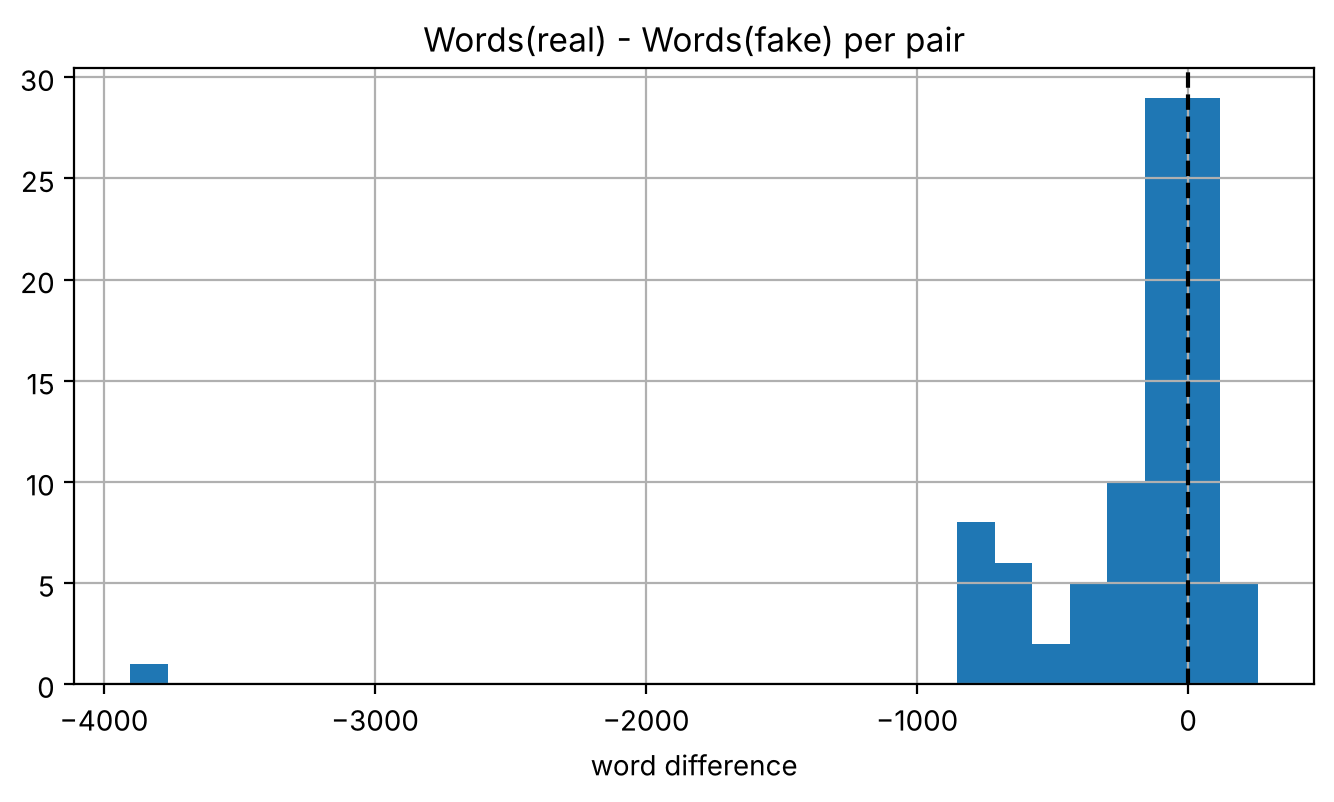

real text longer in 24.2 % of pairs


In [14]:
diff = real_f["n_words"] - fake_f["n_words"]
diff.hist(bins=30)
plt.axvline(0, color="k", ls="--")
plt.title("Words(real) - Words(fake) per pair"); plt.xlabel("word difference"); plt.show()
print("real text longer in", round((diff > 0).mean() * 100, 1), "% of pairs")

**Interpretation.** Most of the mass is left of zero: in about 75% of pairs the real text is
**shorter** than the fake. The rule "pick the shorter text" alone would already be right in about
three out of four pairs. The long left tail shows the fakes that "keep talking" for thousands of words.

### 3.6 Non-Latin characters
The organizers mention that some fake summaries contain letters from other scripts.

In [15]:
def non_latin_letters(t):
    return [c for c in t if c.isalpha() and not c.isascii()]

long["n_non_latin"] = long["text"].map(lambda t: len(non_latin_letters(t)))
print(long.groupby("label")["n_non_latin"].agg(
    mean="mean", median="median", share_with_any=lambda s: (s > 0).mean()).round(3))
fake_chars = Counter(c for t in long.loc[long.is_real == 0, "text"] for c in non_latin_letters(t))
print("Most common non-Latin letters in FAKE texts:", fake_chars.most_common(15))

          mean  median  share_with_any
label                                 
fake   243.453     0.0           0.337
real     0.305     0.0           0.147
Most common non-Latin letters in FAKE texts: [('о', 877), ('а', 818), ('н', 672), ('ا', 541), ('е', 521), ('с', 489), ('и', 479), ('р', 461), ('ل', 428), ('д', 369), ('к', 354), ('т', 350), ('в', 346), ('л', 270), ('у', 268)]


**Interpretation.** About 34% of fake texts contain non-Latin letters (on average ~240 per text),
against about 15% of real texts with only a handful (accented names such as "é").
The most frequent foreign letters in fakes are **Cyrillic** (о, а, н, е …) and **Arabic** (ا, ل, م …).
This is a strong signal when present, but it only covers about a third of the fakes.

### 3.7 Most frequent words (real vs fake)

In [16]:
STOP = set("the a an of and to in is are was were for on with as by that this it from at be its or which their have has can these also".split())
def top_words(texts, n=15):
    c = Counter(w for t in texts for w in re.findall(r"[a-z']+", t.lower()) if w not in STOP and len(w) > 2)
    return c.most_common(n)

pd.concat([pd.DataFrame(top_words(long.loc[long.is_real == 1, "text"]), columns=["real word", "real n"]),
           pd.DataFrame(top_words(long.loc[long.is_real == 0, "text"]), columns=["fake word", "fake n"])], axis=1)

,real word,real n,fake word,fake n
0,stars,111,our,115
1,data,91,like,88
2,observations,77,data,83
3,galaxies,77,about,77
4,telescope,66,stars,73
5,using,64,galaxies,68
6,high,63,how,66
7,will,61,using,65
8,star,60,they,61
9,like,59,into,60


**Interpretation.** Both lists are dominated by astronomy vocabulary (stars, data, galaxies,
telescope), so fakes are usually *on topic* at the word level. Fakes use more conversational words
("our", "like", "about", "how", "they"), which matches the casual tone seen in 3.2, while real texts
mention concrete ESO terms ("eso", "vlt") more often. Topic words alone will not separate the classes.

### 3.8 Train vs test
If the test texts look very different from train, cross-validation scores will be optimistic.

In [17]:
tf = features_frame(test_long["text"])
pd.DataFrame({"train mean": feats[cols].mean(), "test mean": tf[cols].mean()}).round(3)

,train mean,test mean
n_words,322.089,283.621
avg_word_len,5.519,5.571
avg_sent_len,20.798,24.777
type_token_ratio,0.678,0.696
latin_ratio,0.975,0.988
non_ascii_ratio,0.015,0.010
punct_ratio,0.026,0.025
exclam_count,1.263,1.323
digit_ratio,0.007,0.006


**Interpretation.** Averages are similar, but test texts are on average a bit shorter and have
longer sentences and fewer non-ASCII characters. The test set (11× larger) probably contains
manipulation styles that are rare in train, so we should expect the Kaggle score to be somewhat
lower than our validation score.

### 3.9 Summary of EDA findings
- Very small training set (95 pairs) → simple, regularised models and cross-validation.
- Balanced target → accuracy is a fair metric, random baseline ≈ 50%.
- Strongest pairwise signals: **length**, **exclamation marks**, **line breaks**, **digits**; non-Latin letters for about a third of the fakes.
- Outliers (very long or empty texts) are informative and must be kept.
- Hardest cases: fakes that are near-copies of the real text with a few words changed.

## 4. Preprocessing

| Step | Decision | Why |
|---|---|---|
| Reading files | UTF-8 with `errors="replace"`, strip surrounding whitespace (`src/data.py`) | Some fakes contain broken Unicode; reading must never crash. |
| Missing / empty texts | **Keep** empty texts, no imputation | In train an empty text is always the fake → it is a signal, not noise. There are no NaNs to impute. |
| Outliers (very long texts) | **Keep** | Extreme length is the behaviour we want to detect (3.3). |
| Text cleaning | **No** lowercasing, stop-word removal, punctuation or non-Latin stripping | Usual NLP cleaning would delete the signals we found: "!", line breaks, foreign letters, casing. |
| Encoding | Hand-crafted statistics (`src/utils.text_features`) and character n-gram TF-IDF (`char_wb`, 2–4 chars) | Models need numbers. Character n-grams capture spelling, punctuation and foreign scripts and work with little data. |
| Pairwise representation | Features of the pair = `f(text_1) − f(text_2)` | The question is relative ("which one is more real?"), so the model should see the difference. |
| Scaling | `StandardScaler` before logistic regression (hand-crafted features) | Features have very different ranges (`n_chars` in thousands, ratios in [0, 1]). |
| Augmentation | Swap the two texts: features become `−x`, label flips | Doubles 95 → 190 training examples and prevents the model from learning a position bias. |

The cells below show these steps on the training data.

In [18]:
X1, X2 = features_frame(train["text_1"]), features_frame(train["text_2"])
X_diff = (X1 - X2)
y = get_target(train)
print("pairwise feature matrix:", X_diff.shape)
print("feature ranges before scaling:")
X_diff.describe().loc[["min", "max", "std"]].T.round(3).head(6)

pairwise feature matrix: (95, 14)
feature ranges before scaling:


,min,max,std
n_chars,-8521.000,38648.000,4988.728
n_words,-791.000,3902.000,503.832
n_sentences,-67.000,334.000,40.699
avg_word_len,-6.419,6.249,1.178
avg_sent_len,-27.444,38.000,8.821
type_token_ratio,-0.797,0.739,0.212


**Interpretation.** The difference features live on very different scales (e.g. `n_chars` varies by
thousands, `latin_ratio` by less than 1). Without scaling, logistic regression's regularisation would
treat them unequally, which is why `FeatureDiffLR` uses `StandardScaler` inside its pipeline.

In [19]:
X_aug = np.vstack([X_diff.values, -X_diff.values])
y_aug = np.concatenate([y, 1 - y])
print("before augmentation:", X_diff.shape, "| after swap augmentation:", X_aug.shape)
print("label balance after augmentation:", np.bincount(y_aug))

before augmentation: (95, 14) | after swap augmentation: (190, 14)
label balance after augmentation: [95 95]


**Interpretation.** Swapping the texts doubles the data and makes the labels exactly balanced (95/95),
so the model cannot rely on the position of the real file.

In [20]:
tfidf_demo = TfidfDiffLR().fit(train)
print("TF-IDF vocabulary size (character 2-4 grams):", len(tfidf_demo.vectorizer.vocabulary_))

TF-IDF vocabulary size (character 2-4 grams): 26380


**Interpretation.** Character 2–4 grams give a vocabulary of several thousand dimensions. With
`min_df=2` rare n-grams are dropped, and `sublinear_tf` stops very long fake texts from dominating
the vectors. These are fitted **inside each training fold** during cross-validation to avoid leakage.

## 5. Baseline model

| # | Baseline | Idea |
|---|---|---|
| 1 | Random guess | lower bound (~50%) |
| 2 | Majority class | always predict the most common label |
| 3 | Latin-ratio rule | text with the higher share of Latin letters is real |
| 4 | Feature-diff LogReg | logistic regression on hand-crafted feature differences |
| 5 | TF-IDF-diff LogReg | logistic regression on character n-gram TF-IDF differences |

*Idea adapted from:* the organizers' public baseline notebook,
https://www.kaggle.com/code/dawidx/baseline-solution (Latin-character ratio rule, baseline 3).
The code here is our own implementation in `src/models.py`.

### 5.1 Train / validation split (80 / 20)

In [21]:
tr_part, va_part = train_test_split(train, test_size=0.2, random_state=42,
                                    stratify=train["real_text_id"])
rows = []
for key, cls in ALL_BASELINES.items():
    pred = cls().fit(tr_part).predict(va_part)
    rows.append({"model": cls.name, "val_accuracy": np.mean(pred == va_part["real_text_id"].values)})
print("train:", len(tr_part), "pairs | validation:", len(va_part), "pairs")
pd.DataFrame(rows).sort_values("val_accuracy", ascending=False).round(3)

train: 76 pairs | validation: 19 pairs


,model,val_accuracy
4,LogReg on TF-IDF char n-gram differences,1.000
3,LogReg on handcrafted feature differences,0.947
1,Majority class,0.526
0,Random guess,0.474
2,Rule: higher Latin-char ratio,0.421


**Interpretation.** The validation set has only **19 pairs**, so one mistake changes accuracy by about
5 points. The two logistic regressions are clearly ahead (TF-IDF 19/19 correct, hand-crafted features 18/19),
while random guess, majority class and the Latin rule all stay around or even below 50% — the Latin rule
gets 0.42 here although it is above chance on average. Such swings show that a single split of 95 pairs is
too noisy to compare models, so our main estimate is stratified 5-fold cross-validation, where every pair is
used for validation exactly once.

### 5.2 Stratified 5-fold cross-validation

In [22]:
results, cv_out = [], {}
for key, cls in ALL_BASELINES.items():
    res = cross_validate(cls, train, n_splits=5, seed=42)
    cv_out[key] = res
    results.append({"model": cls.name, "cv_acc_mean": res["mean"], "cv_acc_std": res["std"]})
results = pd.DataFrame(results).sort_values("cv_acc_mean", ascending=False).reset_index(drop=True)
results.round(3)

,model,cv_acc_mean,cv_acc_std
0,LogReg on TF-IDF char n-gram differences,0.937,0.021
1,LogReg on handcrafted feature differences,0.895,0.067
2,Rule: higher Latin-char ratio,0.611,0.118
3,Majority class,0.516,0.021
4,Random guess,0.505,0.092


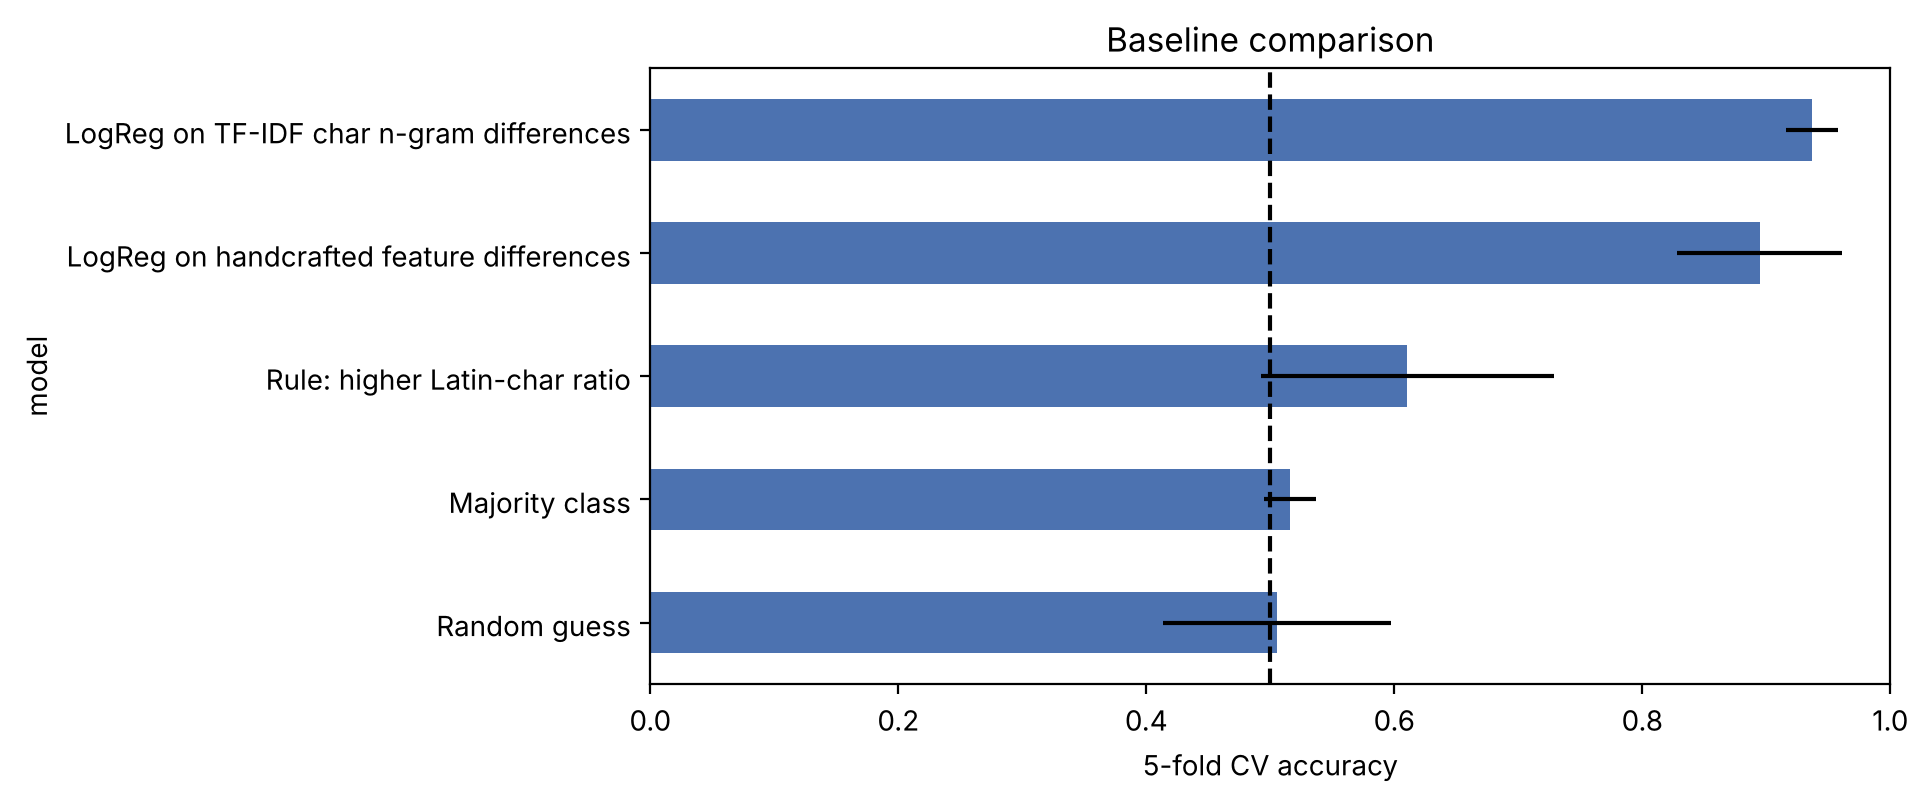

In [23]:
ax = results.plot.barh(x="model", y="cv_acc_mean", xerr="cv_acc_std", legend=False, color="#4C72B0")
ax.axvline(0.5, color="k", ls="--"); ax.set_xlim(0, 1); ax.set_xlabel("5-fold CV accuracy")
plt.title("Baseline comparison"); plt.gca().invert_yaxis(); plt.show()

**Interpretation.**
- Random guess (0.505) and majority class (0.516) confirm the ~50% floor.
- The Latin-ratio rule reaches only **0.611** with a large standard deviation: it can only decide the ~40% of pairs where the two texts differ in Latin share.
- Logistic regression on 14 hand-crafted feature differences jumps to **0.895**.
- TF-IDF character n-grams are the best baseline with **0.937 ± 0.021** and the lowest variance across folds.

### 5.3 Which hand-crafted features matter?

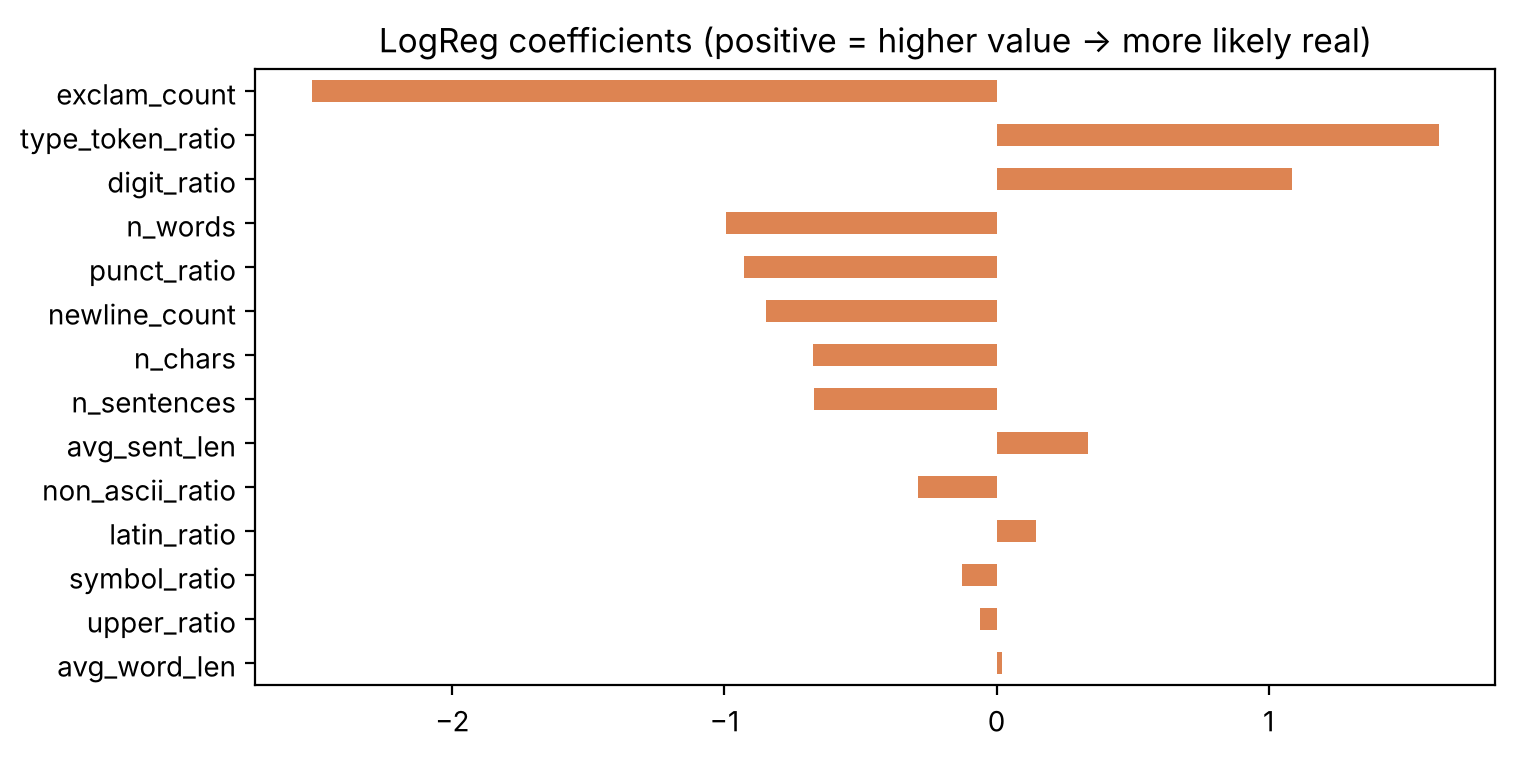

In [24]:
fe_model = FeatureDiffLR().fit(train)
fe_model.feature_importance().plot.barh(color="#DD8452")
plt.title("LogReg coefficients (positive = higher value -> more likely real)")
plt.gca().invert_yaxis(); plt.show()

**Interpretation.** The largest coefficient is negative for `exclam_count`: the text with more "!" is
very likely the fake. Length features (`n_words`, `newline_count`, `n_chars`) and `punct_ratio` are also
negative (longer / more punctuated → fake), while `digit_ratio` is positive (more numbers → real), in line with the EDA.
`type_token_ratio` gets a positive weight although it looked useless alone (3.4): once length is
controlled for, a richer vocabulary points to the real text. Coefficients are on standardised features,
so their sizes are comparable.

### 5.4 Error analysis — pairs the best baseline gets wrong

In [25]:
best_key = max(cv_out, key=lambda k: cv_out[k]["mean"])
wrong = train[cv_out[best_key]["oof"] != train["real_text_id"].values]
print(f"best baseline: {ALL_BASELINES[best_key].name} | wrong on {len(wrong)} / {len(train)} pairs")
for _, row in wrong.head(2).iterrows():
    k = int(row.real_text_id)
    print(f"\n===== article {row.id} (real = file_{k}) =====")
    print("[REAL]", row[f"text_{k}"][:400])
    print("[FAKE]", row[f"text_{3-k}"][:400])

best baseline: LogReg on TF-IDF char n-gram differences | wrong on 6 / 95 pairs

===== article 65 (real = file_1) =====
[REAL] The SPHERE instrument is designed for high-quality imaging of many stars, and its operational plan, particularly a significant survey backed by its development team, will enable the direct detection of several giant planets in different environments. Completing this work on schedule will make an important contribution to the competitive field of extrasolar planet research, including their formatio
[FAKE] The SPHERE instrument is designed to capture very clear images of stars, and its operation plan, particularly a significant survey backed by its development group, will enable the direct detection of several giant planets in different environments. Completing this work on schedule will make an important contribution to the competitive field of extrasolar planet research, including their formation,

===== article 69 (real = file_2) =====
[REAL] The antennas will

**Interpretation.** The remaining errors are pairs where the fake is almost a copy of the real text,
with only a few words or spellings changed (e.g. *fibre* → *fiber*). Surface statistics and character
n-grams cannot tell these apart; they require understanding the *meaning* of the text.

## 6. Kaggle submission
The competition is closed, so we use a **late submission**. The best baseline (TF-IDF-diff LogReg)
is trained on all 95 pairs and predicts the 1,068 test pairs.

In [26]:
best_model = ALL_BASELINES[best_key]().fit(train)
pred = best_model.predict(test)
sub = save_submission(test["id"], pred, "submission.csv")
print(sub["real_text_id"].value_counts())
sub.head()

real_text_id
1    564
2    504
Name: count, dtype: int64


,id,real_text_id
0,0,2
1,1,2
2,2,1
3,3,1
4,4,2


In [27]:
# Submit from Colab (max 3 submissions/day):
# !kaggle competitions submit -c {COMPETITION} -f submission.csv -m "A1 baseline: TF-IDF-diff LogReg"

**Result (late submission, 9 Nov 2026):** public score **0.87136** — screenshot in `submissions/`.

**Interpretation.** The Kaggle score is lower than the CV estimate (0.937). With only 95 training pairs
the model sees few examples of each manipulation type, and the much larger test set contains styles that
are rare in train (see 3.8). The predicted labels are roughly balanced (564 vs 504), so the model is not
simply guessing one side.

## 7. Conclusion

| Model | 80/20 val. accuracy | 5-fold CV accuracy | Kaggle public |
|---|---|---|---|
| Random guess | 0.474 | 0.505 ± 0.092 | – |
| Majority class | 0.526 | 0.516 ± 0.021 | – |
| Latin-ratio rule | 0.421 | 0.611 ± 0.118 | – |
| Feature-diff LogReg | 0.947 | 0.895 ± 0.067 | – |
| TF-IDF-diff LogReg | 1.000 | **0.937 ± 0.021** | **0.871** |

**Key findings**
- Fake summaries are usually longer, use more exclamation marks and line breaks, contain fewer digits, and about a third include Cyrillic or Arabic letters.
- Treating the task as a **comparison** (feature differences + swap augmentation) is what makes simple models work: 0.90–0.94 CV accuracy.
- The organizers' Latin-character rule alone is weak (0.61) because most pairs contain no foreign characters.
- The best baseline reaches **0.871** on Kaggle; the gap to CV shows the limits of 95 training pairs.

**Next steps (Assignment 2)**
- Use a pre-trained language model (e.g. perplexity under a reference LLM, or a fine-tuned DeBERTa/RoBERTa cross-encoder on the pair) to judge *meaning and fluency*, not just surface statistics.
- Compare the two texts directly (word-level diff, semantic similarity to each other) to catch near-copies.
- Combine rule-based, hand-crafted and learned models in an ensemble and validate with repeated CV.